# Figure 4 — WGS tumour/normal (truth) vs targeted panel

Somatic **PURPLE** output (PASS calls) for two sample groups, each with the same two arms:
**WGS tumour/normal** — the golden standard — and the tumour-only **targeted panel** under test.
Everything is restricted to the panel's capture regions, so both arms are compared over the
same territory, and to a tumour VAF >= 10% inclusion gate.

| Panel | Content |
|-------|---------|
| **A** | Variant burden — SNV + MNV and indel, per sample, WGS truth vs targeted panel |
| **B** | Venn diagrams (WGS ∩ panel) — SNV + MNV and indel, per sample group |
| **C** | Panel somatic likelihood (`SOM_LH`) of true vs false positives, per sample group |
| **D** | Gene-level driver likelihood of TP / FN / FP variants, per sample group |

Treating WGS as truth: **TP** = called by both arms, **FN** = WGS only (missed by the panel),
**FP** = panel only (extra — germline leakage is expected here, as the panel is tumour-only).

Point the Configuration cell at other runs — or your own oncoanalyser output — and run all
cells; see **Data access** below.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

### What this notebook reads (~60 MB)

Sixteen run folders: 4 cell lines and 2 patients, each with a WGS tumour/normal arm and a
tumour-only targeted-panel arm.

```text
gs://hartwig-oapaper-celllines/<cell line>/wgs/illumina_novaseq6000/bwa/tn/oa3/    WGS arm
gs://hartwig-oapaper-celllines/<cell line>/panel/illumina_novaseq6000/bwa/to/oa3/  panel arm
gs://hartwig-oapaper-patients/<patient>/wgs/ff/illumina_novaseq6000/bwa/tn/oa3/    WGS arm
gs://hartwig-oapaper-patients/<patient>/panel/illumina_novaseq6000/bwa/to/oa3/     panel arm

  purple/<tumour>.purple.somatic.vcf.gz               every panel
  purple/<tumour>.purple.driver.catalog.somatic.tsv   panel D
  bamtools/<tumour>/<tumour>.bam_metric.target_regions.tsv   the comparison region (panel only)
```

`<cell line>` is COLO829, HCC1187, HCC1395 or HCC1954 — HG008 has no panel run, so it is not
in this figure.

**The comparison region needs no reference file.** By default it is read from the panel runs'
own `bam_metric.target_regions.tsv`, which lists the capture intervals the run actually used.
That territory is identical, base for base, to the HMF oncopanel v3 capture BED, which is not
publicly distributed; set `PANEL_BED` in the Configuration cell if you do have your own copy.

**The patient bucket is not yet public.** The patient group needs read access to
`gs://hartwig-oapaper-patients`; the cell-line group runs from the fully public cell-line
bucket alone, and unreachable patient runs are reported and dropped rather than fatal.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs (sizes above), then repoint the
Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for CL in COLO829 HCC1187 HCC1395 HCC1954; do
  gcloud storage rsync -r \
    gs://hartwig-oapaper-celllines/$CL/wgs/illumina_novaseq6000/bwa/tn/oa3 \
    $DEST/celllines/$CL/wgs/illumina_novaseq6000/bwa/tn/oa3
  gcloud storage rsync -r \
    gs://hartwig-oapaper-celllines/$CL/panel/illumina_novaseq6000/bwa/to/oa3 \
    $DEST/celllines/$CL/panel/illumina_novaseq6000/bwa/to/oa3
done          # ~3.4 GB for the eight complete cell-line run folders
for S in H00005238 H00006429; do
  gcloud storage rsync -r \
    gs://hartwig-oapaper-patients/$S/wgs/ff/illumina_novaseq6000/bwa/tn/oa3 \
    $DEST/patients/$S/wgs/ff/illumina_novaseq6000/bwa/tn/oa3
  gcloud storage rsync -r \
    gs://hartwig-oapaper-patients/$S/panel/illumina_novaseq6000/bwa/to/oa3 \
    $DEST/patients/$S/panel/illumina_novaseq6000/bwa/to/oa3
done
```

Then, in the Configuration cell:

```python
CELLLINES_ROOT = "/absolute/path/to/oapaper-data/celllines"
PATIENTS_ROOT  = "/absolute/path/to/oapaper-data/patients"
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The
only requirement is that the directory contains the tool sub-folders listed above; the
sample names are read from the files themselves, so they do not have to match ours.


## 1 · Configuration

In [ ]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# Each arm of each group is a {sample id: run folder} map. A run folder is one
# oncoanalyser output directory — local path or gs:// URI — holding purple/,
# bamtools/ and the rest directly (no results/<subject> level). The sample id
# is what the two arms are matched on, and what the figure labels; both arms of
# a group must use the same ids. cellline_run() and patient_run() build the
# folders from the scheme described in Data access above.
# ============================================================================
CELLLINES_ROOT = "gs://hartwig-oapaper-celllines"   # or an absolute path to a local copy
PATIENTS_ROOT  = "gs://hartwig-oapaper-patients"    # not yet public: the patient group needs access

PATIENT_SAMPLES   = ["H00005238", "H00006429"]              # consented for this figure
CELL_LINE_SAMPLES = ["COLO829", "HCC1187", "HCC1395", "HCC1954"]   # HG008 has no panel run
PLATFORM          = "illumina_novaseq6000"

def cellline_run(cell_line, modality, run_type, platform=PLATFORM):
    """<CELLLINES_ROOT>/<cell line>/<wgs|panel>/<platform>/bwa/<tn|to>/oa3"""
    return (f"{str(CELLLINES_ROOT).rstrip('/')}/{cell_line}/{modality}"
            f"/{platform}/bwa/{run_type}/oa3")

def patient_run(sample, modality, run_type, preservation="ff", platform=PLATFORM):
    """<PATIENTS_ROOT>/<sample>/wgs/<ff|ffpe>/<platform>/bwa/<tn|to>/oa3, or .../panel/... for the panel."""
    mid = f"wgs/{preservation}" if modality == "wgs" else modality
    return f"{str(PATIENTS_ROOT).rstrip('/')}/{sample}/{mid}/{platform}/bwa/{run_type}/oa3"

# The two arms, styled globally. The source runs differ per sample group (see GROUPS).
MODALITIES = OrderedDict([
    ("WGS",   {"color": "#22876B", "label": "WGS T/N (truth)"}),
    ("PANEL", {"color": "#CC3B2E", "label": "Targeted panel"}),
])
TRUTH, TEST = "WGS", "PANEL"          # WGS tumour/normal is the golden standard

# Sample groups. Each group has the same two arms but its own runs. `samples` both restricts and
# orders what is shown; every id in it must appear in both arms of that group.
GROUPS = OrderedDict([
    ("cell_lines", {
        "label": "cell lines",
        "samples": CELL_LINE_SAMPLES,
        "arms": {
            "WGS":   {"runs": {c: cellline_run(c, "wgs", "tn")   for c in CELL_LINE_SAMPLES}},
            "PANEL": {"runs": {c: cellline_run(c, "panel", "to") for c in CELL_LINE_SAMPLES}},
        },
    }),
    ("patients", {
        "label": "patients",
        "samples": PATIENT_SAMPLES,
        "arms": {
            "WGS":   {"runs": {s: patient_run(s, "wgs", "tn")   for s in PATIENT_SAMPLES}},
            "PANEL": {"runs": {s: patient_run(s, "panel", "to") for s in PATIENT_SAMPLES}},
        },
    }),
])

# Comparison region — the targeted panel's capture intervals, so both arms are scored over the
# same territory. None (the default) reads them from the panel runs' own bamtools
# target_regions table, which needs no reference file; set a path or gs:// URI to a capture BED
# to override, or leave PANEL_BED None and set USE_TARGET_REGIONS False to compare genome-wide.
PANEL_BED           = None
USE_TARGET_REGIONS  = True

VAF_MIN = 0.10        # tumour FORMAT AF gate, applied to the burden panel and the benchmark
# ============================================================================

# Downloaded inputs are cached under data/figure_4/<run-folder>/, keyed on the folders above, so
# switching runs re-fetches rather than reusing the previous run's files. Delete to refresh.
CACHE_ROOT = Path("data") / "figure_4"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)

for _g, _cfg in GROUPS.items():
    print(f"{_g:11s} {_cfg['samples']}")
    for _a, _arm in _cfg["arms"].items():
        print(f"            {_a:5s} {next(iter(_arm['runs'].values()))}")
_region = "panel BED" if PANEL_BED else ("panel target regions" if USE_TARGET_REGIONS else "genome-wide")
print(f"truth={TRUTH}  test={TEST}  VAF gate={VAF_MIN}  region={_region}")

## 2 · Locating pipeline output

Resolves the folders configured above to the directories that hold the per-tool outputs, and
provides the local / `gs://` read helpers used by the loading section. Nothing is downloaded here.

In [ ]:
import subprocess, re, hashlib
from pathlib import Path

# ---- IO: identical behaviour for local paths and gs:// URIs -----------------------------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a run that skipped a step degrades to a blank panel instead of a crash.
    dest = Path(dest)
    if dest.exists():
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if _is_remote(src):
        if _gsutil("cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same arm live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-6:]   # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

# ---- Subject discovery ------------------------------------------------------------------------
# In this layout a run folder *is* the subject directory: purple/, alignments/, bamtools/, logs/
# and the rest sit directly inside it, with no results/<subject> level. Sample names are still
# read out of the output rather than assumed, so runs whose samples are named differently
# (COLO829v012T, HCC1187BL, ...) need no configuration. PURPLE output is the marker, because
# runs started from pre-existing BAMs do not always republish an alignments/ folder.
_PURITY_SUFFIX = ".purple.purity.tsv"

def find_tumour(base):
    """Tumour sample name of one run folder, from <base>/purple/<tumour>.purple.purity.tsv.

    Returns None when the run simply has no PURPLE output, and raises when the location cannot
    be read at all (no credentials, no access, wrong bucket). Callers turn that into a single
    warning for the whole arm, so a permissions problem is never mistaken for an empty run.
    """
    hits = _glob(base, f"purple/*{_PURITY_SUFFIX}", dirs_only=False)
    return hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)] if hits else None

def _unreadable(base, err):
    print(f"WARN: cannot read {base}\n      {str(err).strip().splitlines()[-1]}")

def group_arm_subjects(group, arm):
    """[(sid, tumour_sample, base), ...] for one group and arm, in configured order.

    The sid is the key from the Configuration cell, not a directory name, so the two arms line
    up for variant matching however their runs and samples happen to be named.
    """
    found = []
    for sid, base in GROUPS[group]["arms"][arm]["runs"].items():
        try:
            tumor = find_tumour(base)
        except RuntimeError as e:      # the whole location is unreadable, not just this run
            _unreadable(base, e)
            break
        if tumor is None:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {group}/{arm}/{sid}")
            continue
        found.append((sid, tumor, base))
    return found

print("path helpers ready")

## 3 · Plotting style

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Panel A display groups: SNV and MNV share one bar (MNVs are near-absent here, and the benchmark
# pools them anyway), leaving "SNV + MNV" and "indel".
VAR_TYPES     = ["SNV", "MNV", "indel"]
BURDEN_GROUPS = [("SNV + MNV", ["SNV", "MNV"]), ("indel", ["indel"])]

# Benchmark categories. TP/FP are panel calls, FN is WGS-only.
KINDS      = ["snvmnv", "indel"]
KIND_LABEL = {"snvmnv": "SNV + MNV", "indel": "Indel"}

# Panel C — per-variant somatic likelihood (SOM_LH): an orange ramp, dark = HIGH.
SOMLH_ORDER  = ["HIGH", "MEDIUM", "LOW"]
SOMLH_STACK  = SOMLH_ORDER + ["NA"]              # NA (grey) is drawn only when present
SOMLH_COLORS = {"HIGH": "#8A3B0B", "MEDIUM": "#C1651A", "LOW": "#F0C9A6", "NA": "#CFCFCF"}

# Panel D — gene-level driverLikelihood: a distinct blue ramp, deliberately NOT the orange SOM_LH
# ramp, so the two (different) quantities are never read as the same scale.
DLIK_BINS   = [("HIGH", 0.8, 1.01), ("MEDIUM", 0.2, 0.8), ("LOW", 0.0, 0.2)]
DLIK_ORDER  = ["HIGH", "MEDIUM", "LOW", "none"]
DLIK_COLORS = {"HIGH": "#08519C", "MEDIUM": "#4292C6", "LOW": "#9ECAE1", "none": "#E5E5E5"}

def _text_color(facecolor):
    r, g, b = mpl.colors.to_rgb(facecolor)
    return "black" if (0.299 * r + 0.587 * g + 0.114 * b) > 0.55 else "white"

def _group_title(g):
    return f"{GROUPS[g]['label']}  (SNV+MNV+indel pooled)"

ARM_HANDLES = [Line2D([0], [0], marker="s", ls="", ms=8, color=MODALITIES[m]["color"],
                      label=MODALITIES[m]["label"]) for m in MODALITIES]

## 4 · Load PURPLE output — WGS truth vs targeted panel

One pass over each sample's PURPLE somatic VCF, restricted to the comparison region, yields
everything the four panels need:

- **`counts`** — SNV / MNV / indel counts at VAF ≥ 10% (panel A)
- **`pervar`** — `key -> tumour VAF` per PASS variant, split into `snvmnv` and `indel`; the VAF gate
  is applied later so a variant can qualify on either arm (panel B)
- **`somlh`** — the panel's per-variant `SOM_LH` ∈ {HIGH, MEDIUM, LOW} (panel C)
- **`dlik`** — each variant's `IMPACT` gene mapped to that gene's `driverLikelihood` in the PURPLE
  somatic driver catalog, or `None` when the gene has no catalog entry (panel D)

Variants are keyed `(chrom, pos, ref, alt)`, which is what matches the two arms against each other.
The comparison region is built once — from the panel runs' own `bam_metric.target_regions.tsv`,
or from `PANEL_BED` if you set one — and indexed per chromosome for fast membership testing.

In [ ]:
import gzip
from collections import Counter
import numpy as np
import pandas as pd

# ---- Comparison region: the targeted panel's capture intervals --------------------------------
# Both arms are scored over the panel's territory only. Two sources, in order of preference:
#   PANEL_BED            an explicit capture BED (0-based half-open), if you have one
#   USE_TARGET_REGIONS   the panel runs' own bamtools target_regions table (1-based inclusive),
#                        which every published panel run carries and which covers exactly the
#                        same bases as the capture BED, with adjacent probes already merged.
def _index_regions(intervals):
    """{'starts','ends'} per chromosome from 0-based half-open intervals, overlaps merged."""
    by_chrom = {}
    for ch, s, e in intervals:
        by_chrom.setdefault(ch, []).append((s, e))
    starts, ends = {}, {}
    for ch, iv in by_chrom.items():
        merged = []
        for s, e in sorted(iv):
            if merged and s <= merged[-1][1]:
                merged[-1][1] = max(merged[-1][1], e)
            else:
                merged.append([s, e])
        starts[ch] = np.asarray([m[0] for m in merged])
        ends[ch] = np.asarray([m[1] for m in merged])
    return {"starts": starts, "ends": ends}

def load_bed(bed_src):
    """0-based half-open intervals from a BED (plain or gzipped; local path, gs:// or https://)."""
    dest = _fetch(bed_src, CACHE_ROOT / "regions" / str(bed_src).rsplit("/", 1)[-1])
    if dest is None:
        raise FileNotFoundError(f"capture BED not found: {bed_src}")
    opener = gzip.open if str(dest).endswith(".gz") else open
    out = []
    with opener(dest, "rt") as f:
        for line in f:
            if not line.strip() or line.startswith(("track", "browser", "#")):
                continue
            ch, s, e = line.split("\t")[:3]
            out.append((ch, int(s), int(e)))
    return out

def load_target_regions(base, sample):
    """0-based half-open intervals from one panel run's bamtools target_regions table."""
    dest = _fetch(f"{base}/bamtools/{sample}/{sample}.bam_metric.target_regions.tsv",
                  CACHE_ROOT / "regions" / f"{sample}.target_regions.tsv")
    if dest is None:
        return None
    df = pd.read_csv(dest, sep="\t", usecols=["Chromosome", "PositionStart", "PositionEnd"])
    return [(c, int(s) - 1, int(e)) for c, s, e in df.itertuples(index=False)]

def build_region():
    if PANEL_BED:
        return load_bed(PANEL_BED), f"capture BED {PANEL_BED}"
    if not USE_TARGET_REGIONS:
        return None, "genome-wide"
    intervals, seen = [], []
    for group in GROUPS:
        for sid, tumor, base in group_arm_subjects(group, TEST):
            iv = load_target_regions(base, tumor)
            if iv:
                intervals += iv
                seen.append(sid)
    if not intervals:
        raise FileNotFoundError(
            "No target_regions table found in any panel run, and PANEL_BED is not set.\n"
            "  Set PANEL_BED to a capture BED, or USE_TARGET_REGIONS = False to compare genome-wide.")
    return _index_regions(intervals), f"panel target regions ({', '.join(seen)})"

REGION, REGION_SOURCE = build_region()
if REGION:
    print(f"comparison region: {sum(len(v) for v in REGION['starts'].values()):,} intervals over "
          f"{len(REGION['starts'])} contigs, {sum(int((REGION['ends'][c] - REGION['starts'][c]).sum()) for c in REGION['starts']):,} bp "
          f"-- from {REGION_SOURCE}")
else:
    print("comparison region: genome-wide")

def in_region(chrom, pos):
    # pos is 1-based (VCF); the region index is 0-based half-open, sorted and merged.
    if REGION is None:
        return True
    st = REGION["starts"].get(chrom)
    if st is None:
        return False
    p0 = pos - 1
    i = int(np.searchsorted(st, p0, side="right")) - 1
    return i >= 0 and p0 < REGION["ends"][chrom][i]

# ---- Parsing ----------------------------------------------------------------------------------
def _tumor_vaf(fmt_field, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt_field.split(":")
    if "AF" not in keys:
        return np.nan
    try:
        return float(sample.split(":")[keys.index("AF")])
    except (ValueError, IndexError):
        return np.nan

def parse_somatic(path):
    """One pass over a PURPLE somatic VCF, restricted to the comparison region.

    Returns (counts, pervar, somlh, genes):
      counts  {'SNV'|'MNV'|'indel': n}          PASS and VAF >= VAF_MIN
      pervar  {'snvmnv'|'indel': {key: vaf}}    PASS, no VAF gate (applied by the benchmark)
      somlh   {key: SOM_LH}                     'NA' where the field is absent (the WGS arm)
      genes   {key: gene or None}               from the INFO IMPACT field
    """
    counts = {vt: 0 for vt in VAR_TYPES}
    pervar = {"snvmnv": {}, "indel": {}}
    somlh, genes = {}, {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS" or not in_region(c[0], int(c[1])):
                continue
            ref, alt = c[3], c[4].split(",")[0]
            if ref == alt:
                continue
            key = (c[0], c[1], ref, alt)
            rl, al = len(ref), len(alt)
            vt = "SNV" if (rl == 1 and al == 1) else ("MNV" if rl == al else "indel")
            pervar["indel" if vt == "indel" else "snvmnv"][key] = _tumor_vaf(c[8], c[-1])

            info = c[7]
            m = re.search(r"(?:^|;)SOM_LH=([A-Z]+)", info)
            somlh[key] = m.group(1) if m else "NA"
            m = re.search(r"(?:^|;)IMPACT=([^;,]+)", info)
            genes[key] = m.group(1) if m else None

            vaf = pervar["indel" if vt == "indel" else "snvmnv"][key]
            if not np.isnan(vaf) and vaf >= VAF_MIN:
                counts[vt] += 1
    return counts, pervar, somlh, genes

def load_gene_driverlik(path):
    # gene -> driverLikelihood from the PURPLE somatic driver catalog (max over that gene's rows).
    if path is None:
        return {}
    df = pd.read_csv(path, sep="\t")
    if not {"gene", "driverLikelihood"} <= set(df.columns):
        return {}
    df = df.dropna(subset=["gene", "driverLikelihood"])
    return df.groupby("gene")["driverLikelihood"].max().to_dict()

def load_sample(base, tumor, dest):
    som = _fetch(f"{base}/purple/{tumor}.purple.somatic.vcf.gz", dest / f"{tumor}.somatic.vcf.gz")
    if som is None:
        print(f"WARN: skipping {tumor} -- no PURPLE somatic VCF under {base}/purple/")
        return None
    dc = _fetch(f"{base}/purple/{tumor}.purple.driver.catalog.somatic.tsv",
                dest / f"{tumor}.driver.catalog.somatic.tsv")
    counts, pervar, somlh, genes = parse_somatic(som)
    glik = load_gene_driverlik(dc)
    return {"tumor": tumor, "counts": counts, "pervar": pervar, "somlh": somlh,
            "dlik": {k: (glik.get(g) if g else None) for k, g in genes.items()}}

# ---- Load every group x arm -------------------------------------------------------------------
# DATA[arm][sid] -> sample dict; SAMPLE_GROUP[sid] -> group; GROUP_SAMPLES[group] -> ordered sids.
DATA = {m: {} for m in MODALITIES}
SAMPLE_GROUP, GROUP_SAMPLES = {}, {}
for group in GROUPS:
    for arm in MODALITIES:
        for sid, tumor, base in group_arm_subjects(group, arm):
            s = load_sample(base, tumor, cache_dir(CACHE_ROOT, base, arm, sid))
            if s is not None:
                DATA[arm][sid] = s
                SAMPLE_GROUP[sid] = group
    want = GROUPS[group]["samples"]
    GROUP_SAMPLES[group] = [s for s in want if all(s in DATA[m] for m in MODALITIES)]
    missing = [s for s in want if s not in GROUP_SAMPLES[group]]
    if missing:
        print(f"WARN: {group} -- not present in both arms, dropped: {missing}")

ALL_SAMPLES = [s for g in GROUPS for s in GROUP_SAMPLES[g]]
for g in GROUPS:
    print(f"{g:11s} {GROUP_SAMPLES[g]}")
for m in MODALITIES:
    for s in ALL_SAMPLES:
        c = DATA[m][s]["counts"]; pv = DATA[m][s]["pervar"]
        print(f"  {m:5s} {s:11s} SNV={c['SNV']:<6d} MNV={c['MNV']:<4d} indel={c['indel']:<5d} "
              f"| region SNV+MNV={len(pv['snvmnv']):<6d} indel={len(pv['indel'])}")

## 5 · Benchmark — TP / FN / FP

Matching the two arms by `chrom:pos:ref:alt` inside the comparison region, with the VAF ≥ 10%
inclusion gate (a variant is kept if it reaches the gate on **at least one** arm; membership itself
is PASS presence):

- **TP** — called by both arms
- **FN** — WGS only, i.e. missed by the panel
- **FP** — panel only, i.e. extra calls (germline leakage expected, the panel being tumour-only)

with **Recall = TP/(TP+FN)**, **Precision = TP/(TP+FP)** and **F1 = 2·P·R/(P+R)**. `BENCH[group][kind]`
holds the counts and the per-category variant lists that panels B, C and D all read.

In [6]:
def benchmark(kind, sids):
    """(counts, {'TP'|'FN'|'FP': [(sid, key), ...]}) for one variant kind over the given samples."""
    counts = {"TP": 0, "FN": 0, "FP": 0}
    lists = {"TP": [], "FN": [], "FP": []}
    for sid in sids:
        t = DATA[TRUTH][sid]["pervar"][kind]
        f = DATA[TEST][sid]["pervar"][kind]
        for k in set(t) | set(f):
            vt, vf = t.get(k, np.nan), f.get(k, np.nan)
            if not (((not np.isnan(vt)) and vt >= VAF_MIN) or
                    ((not np.isnan(vf)) and vf >= VAF_MIN)):      # inclusion gate
                continue
            cat = "TP" if (k in t and k in f) else ("FN" if k in t else "FP")
            counts[cat] += 1
            lists[cat].append((sid, k))
    return counts, lists

def metrics(counts):
    tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    pre = tp / (tp + fp) if (tp + fp) else float("nan")
    f1 = 2 * pre * rec / (pre + rec) if (pre + rec) else float("nan")
    return rec, pre, f1

# BENCH[group][kind] -> (counts, lists); one Venn per (group, kind) in panel B.
BENCH = {g: {k: benchmark(k, GROUP_SAMPLES[g]) for k in KINDS} for g in GROUPS}

def cat_pairs(group, cat):
    """[(sid, key), ...] for one group and category, pooling SNV+MNV and indel (panels C and D)."""
    return [p for kind in KINDS for p in BENCH[group][kind][1][cat]]

for scope, sids in ([("POOLED", ALL_SAMPLES)] +
                    [(GROUPS[g]["label"], GROUP_SAMPLES[g]) for g in GROUPS] +
                    [(s, [s]) for s in ALL_SAMPLES]):
    for kind in KINDS:
        c, _ = benchmark(kind, sids); rec, pre, f1 = metrics(c)
        print(f"{scope:11s} {KIND_LABEL[kind]:9s} TP={c['TP']:<5d} FN={c['FN']:<4d} FP={c['FP']:<5d} "
              f"| Recall={rec:.4f} Precision={pre:.4f} F1={f1:.4f}")

POOLED      SNV + MNV TP=130   FN=5    FP=138   | Recall=0.9630 Precision=0.4851 F1=0.6452
POOLED      Indel     TP=11    FN=1    FP=6     | Recall=0.9167 Precision=0.6471 F1=0.7586
cell lines  SNV + MNV TP=112   FN=4    FP=71    | Recall=0.9655 Precision=0.6120 F1=0.7492
cell lines  Indel     TP=9     FN=0    FP=2     | Recall=1.0000 Precision=0.8182 F1=0.9000
patients    SNV + MNV TP=18    FN=1    FP=67    | Recall=0.9474 Precision=0.2118 F1=0.3462
patients    Indel     TP=2     FN=1    FP=4     | Recall=0.6667 Precision=0.3333 F1=0.4444
COLO829     SNV + MNV TP=38    FN=2    FP=10    | Recall=0.9500 Precision=0.7917 F1=0.8636
COLO829     Indel     TP=1     FN=0    FP=0     | Recall=1.0000 Precision=1.0000 F1=1.0000
HCC1187     SNV + MNV TP=19    FN=1    FP=11    | Recall=0.9500 Precision=0.6333 F1=0.7600
HCC1187     Indel     TP=4     FN=0    FP=2     | Recall=1.0000 Precision=0.6667 F1=0.8000
HCC1395     SNV + MNV TP=37    FN=1    FP=11    | Recall=0.9737 Precision=0.7708 F1=0.8605

## 6 · Panel A — variant burden (WGS truth vs targeted panel)

SNV + MNV (left) and indel (right) counts per sample and arm, inside the panel BED and above the
VAF gate. Samples run cell lines first, then patients, separated by a divider.

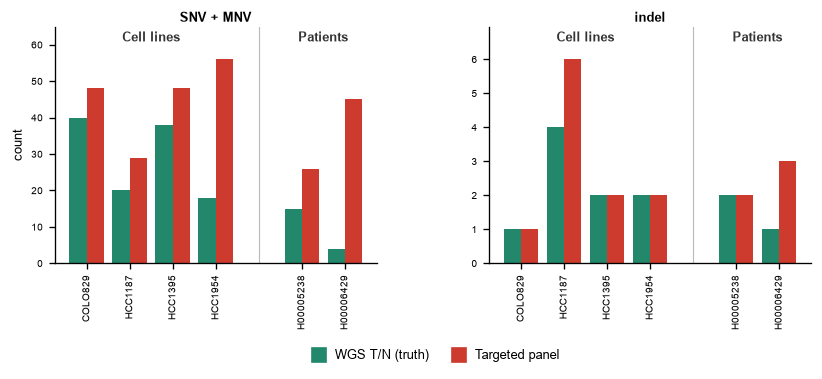

In [7]:
def _grouped_x():
    # x-centre per sample (aligned with ALL_SAMPLES), with a gap between groups; plus each group's span.
    xs, spans, pos, first = [], OrderedDict(), 0.0, True
    for g in GROUPS:
        members = GROUP_SAMPLES[g]
        if not members:
            continue
        if not first:
            pos += 1.0                                     # gap between groups
        first = False
        start = pos
        for _ in members:
            xs.append(pos); pos += 1.0
        spans[g] = (start, pos - 1.0)
    return np.array(xs), spans

def draw_burden(fig, spec):
    # One sub-axes per display group; within each, the two arms side by side per sample.
    mods = list(MODALITIES); w = 0.8 / len(mods)
    xs, spans = _grouped_x()
    sub = spec.subgridspec(1, len(BURDEN_GROUPS), wspace=0.35)
    axes = []
    for k, (label, members) in enumerate(BURDEN_GROUPS):
        ax = fig.add_subplot(sub[0, k])
        for mi, m in enumerate(mods):
            vals = [sum(DATA[m][s]["counts"][vt] for vt in members) for s in ALL_SAMPLES]
            ax.bar(xs + (mi - (len(mods) - 1) / 2) * w, vals, w,
                   color=MODALITIES[m]["color"], zorder=2)
        ax.set_title(label, fontsize=7.5, pad=3)
        ax.set_xticks(xs); ax.set_xticklabels(ALL_SAMPLES, fontsize=6, rotation=90)
        ax.tick_params(axis="y", labelsize=6); ax.margins(y=0.16)
        # divider + group name between the sample groups
        spanlist = list(spans.items())
        for gi in range(len(spanlist) - 1):
            ax.axvline((spanlist[gi][1][1] + spanlist[gi + 1][1][0]) / 2,
                       color="#BBBBBB", lw=0.7, zorder=0)
        if len(spanlist) > 1:
            for g, (a, b) in spanlist:
                ax.text((a + b) / 2, 0.98, GROUPS[g]["label"].capitalize(),
                        transform=ax.get_xaxis_transform(), ha="center", va="top",
                        fontsize=7.5, weight="bold", color="#333333")
        axes.append(ax)
    axes[0].set_ylabel("count")
    return axes

def burden_legend(fig, axes):
    # Arm legend, centred under the sub-axes. Placed in figure coordinates once the axes have been
    # laid out, so it sits the same distance below the rotated sample labels in the standalone
    # preview and in the composite, whatever the figure size.
    fig.canvas.draw()
    p0, p1 = axes[0].get_position(), axes[-1].get_position()
    fig.legend(handles=ARM_HANDLES, loc="upper center",
               bbox_to_anchor=((p0.x0 + p1.x1) / 2, p0.y0 - 0.62 / fig.get_figheight()),
               ncol=len(MODALITIES), fontsize=7.5, handletextpad=0.3, columnspacing=1.4)

fig = plt.figure(figsize=(7.0, 3.4))
axes = draw_burden(fig, fig.add_gridspec(1, 1, left=0.09, right=0.99, top=0.92, bottom=0.34)[0, 0])
burden_legend(fig, axes)
plt.show()

## 7 · Panel B — Venn diagrams (WGS ∩ panel)

One Venn per sample group (rows) and variant kind (columns), samples pooled within a group. The
left circle is the WGS truth set, the right circle the panel; the overlap is TP, the crescents FN
(WGS only) and FP (panel only). Circles are drawn at a fixed size — the numbers, not the areas,
carry the counts.

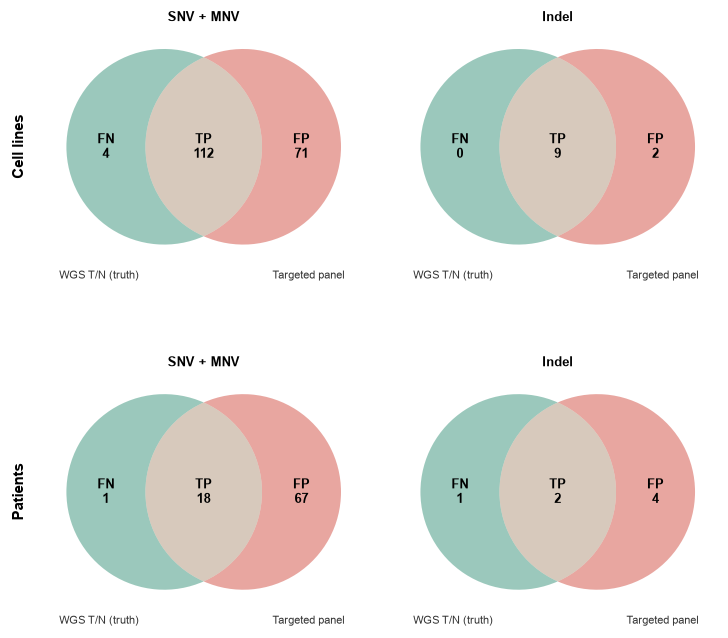

In [8]:
from matplotlib_venn import venn2
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm

# Equal, fixed-size circles: the real subset sizes differ by orders of magnitude, and an
# area-proportional layout collapses the small crescents into invisible slivers.
_VENN_LAYOUT = DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 1))

def _draw_one_venn(ax, counts, title=None):
    tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
    # venn2 subset order = (A only, B only, AB) = (FN, FP, TP); A = WGS truth, B = panel.
    v = venn2(subsets=(1, 1, 1), set_labels=("", ""), alpha=0.45, ax=ax,
              set_colors=(MODALITIES[TRUTH]["color"], MODALITIES[TEST]["color"]),
              layout_algorithm=_VENN_LAYOUT)
    for region, text in (("10", f"FN\n{fn:,}"), ("01", f"FP\n{fp:,}"), ("11", f"TP\n{tp:,}")):
        lbl = v.get_label_by_id(region)
        if lbl:
            lbl.set_text(text); lbl.set_fontsize(7.5); lbl.set_fontweight("bold")
    # arm names under their own circle (venn2 puts them above, where the row labels sit)
    for x, arm in ((0.17, TRUTH), (0.83, TEST)):
        ax.text(x, -0.02, MODALITIES[arm]["label"], transform=ax.transAxes,
                ha="center", va="top", fontsize=6.5, color="#333333")
    if title:
        ax.set_title(title, fontsize=8, weight="bold", pad=4)

def draw_venns(fig, spec):
    groups = [g for g in GROUPS if GROUP_SAMPLES[g]]
    sub = spec.subgridspec(len(groups), len(KINDS), hspace=0.45, wspace=0.05)
    axes = []
    for gi, g in enumerate(groups):
        row = []
        for ki, kind in enumerate(KINDS):
            ax = fig.add_subplot(sub[gi, ki])
            _draw_one_venn(ax, BENCH[g][kind][0], title=KIND_LABEL[kind])
            row.append(ax)
        row[0].text(-0.06, 0.5, GROUPS[g]["label"].capitalize(), transform=row[0].transAxes,
                    rotation=90, ha="right", va="center", fontsize=9, weight="bold")
        axes.append(row)
    return axes

fig = plt.figure(figsize=(6.4, 5.4))
draw_venns(fig, fig.add_gridspec(1, 1, left=0.08, right=0.98, top=0.94, bottom=0.04)[0, 0])
plt.show()

## 8 · Panel C — somatic likelihood of true vs false positives

Every panel call carries a per-variant **somatic likelihood** (`SOM_LH` ∈ {HIGH, MEDIUM, LOW}) — the
panel pipeline's own confidence that the call is genuinely somatic. If the panel-only false
positives are germline leakage or artefacts rather than real somatic calls, they should be depleted
of HIGH-likelihood variants relative to the true positives. TP and FP compositions are shown as
normalised stacked bars, SNV + MNV + indel pooled, one axis per sample group. TP and FP are both
panel calls, so both carry `SOM_LH`. The patient group is two samples — read its fractions with that
small-n caveat.

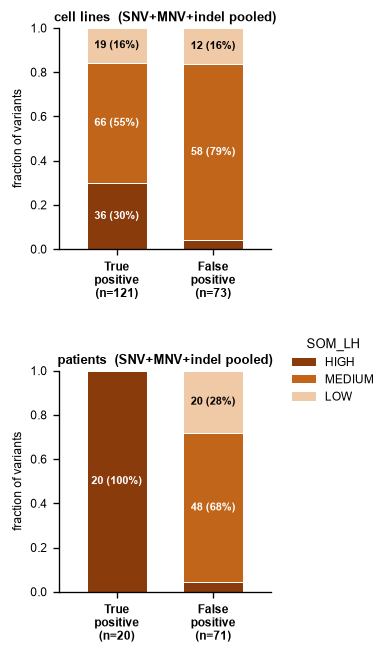

Panel SOM_LH composition (SNV+MNV+indel pooled):
  cell lines  TP: HIGH=36 (30%)  MEDIUM=66 (55%)  LOW=19 (16%)
  cell lines  FP: HIGH=3 (4%)  MEDIUM=58 (79%)  LOW=12 (16%)
  patients    TP: HIGH=20 (100%)
  patients    FP: HIGH=3 (4%)  MEDIUM=48 (68%)  LOW=20 (28%)


In [9]:
def somlh_composition(group, cat):
    c = Counter()
    for sid, key in cat_pairs(group, cat):
        c[DATA[TEST][sid]["somlh"].get(key, "NA")] += 1
    return c

def draw_somlh(fig, spec):
    groups = [g for g in GROUPS if GROUP_SAMPLES[g]]
    cats = [("True\npositive", "TP"), ("False\npositive", "FP")]
    sub = spec.subgridspec(len(groups), 1, hspace=0.55)
    axes = []
    for gi, g in enumerate(groups):
        ax = fig.add_subplot(sub[gi, 0])
        comps = {cat: somlh_composition(g, cat) for _, cat in cats}
        tots = {cat: sum(comps[cat].values()) for _, cat in cats}
        for xi, (_, cat) in enumerate(cats):
            denom = tots[cat] or 1; bottom = 0.0
            for lh in SOMLH_STACK:
                v = comps[cat].get(lh, 0)
                if not v:
                    continue
                h = v / denom
                ax.bar(xi, h, bottom=bottom, width=0.62,
                       color=SOMLH_COLORS[lh], edgecolor="white", lw=0.6)
                if h >= 0.06:
                    ax.text(xi, bottom + h / 2, f"{v} ({v / denom * 100:.0f}%)", ha="center",
                            va="center", fontsize=6.5, weight="bold",
                            color=_text_color(SOMLH_COLORS[lh]))
                bottom += h
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([f"{lab}\n(n={tots[cat]})" for lab, cat in cats],
                           fontsize=7, weight="bold")
        ax.set_xlim(-0.6, len(cats) - 0.4); ax.set_ylim(0, 1.0)
        ax.set_ylabel("fraction of variants", fontsize=7)
        ax.set_title(_group_title(g), fontsize=7.5, pad=4)
        axes.append(ax)
    present = [l for l in SOMLH_STACK
               if any(somlh_composition(g, c).get(l, 0) for g in groups for _, c in cats)]
    fig.legend(handles=[Patch(facecolor=SOMLH_COLORS[l], label=l) for l in present],
               title="SOM_LH", loc="center left", bbox_to_anchor=(1.05, 1.0),
               bbox_transform=axes[-1].transAxes, fontsize=7, title_fontsize=7.5)
    return axes

fig = plt.figure(figsize=(3.4, 5.4))
draw_somlh(fig, fig.add_gridspec(1, 1, left=0.20, right=0.72, top=0.94, bottom=0.07)[0, 0])
plt.show()

print("Panel SOM_LH composition (SNV+MNV+indel pooled):")
for g in GROUPS:
    for cat in ("TP", "FP"):
        comp = somlh_composition(g, cat); tot = sum(comp.values()) or 1
        print(f"  {GROUPS[g]['label']:11s} {cat}: " +
              "  ".join(f"{lh}={comp[lh]} ({comp[lh] / tot * 100:.0f}%)"
                        for lh in SOMLH_STACK if comp.get(lh)))

## 9 · Panel D — driver likelihood of TP / FN / FP variants

A **different** quantity from the per-variant `SOM_LH` of panel C: the PURPLE driver catalog scores
each *gene* with a `driverLikelihood` ∈ [0, 1] (probability that the gene is a driver in that
sample; DNDS / HOTSPOT / BIALLELIC). Each benchmark variant is mapped to its `IMPACT` gene and takes
that gene's likelihood, read from **the arm that called it** — TP and FP from the panel catalog
(both are panel calls), FN from the WGS catalog (FN is WGS-only). Values are binned
**HIGH ≥ 0.8 · MEDIUM 0.2–0.8 · LOW < 0.2 · none** (gene absent from the catalog).

This asks whether the panel misses high-driver-likelihood genes (FN) and whether its extra calls
(FP) sit in low-driver-likelihood genes. Most benchmark variants fall in genes with no catalog
record, so the **none** bin dominates and the HIGH / MEDIUM / LOW comparison concerns the
driver-gene subset.

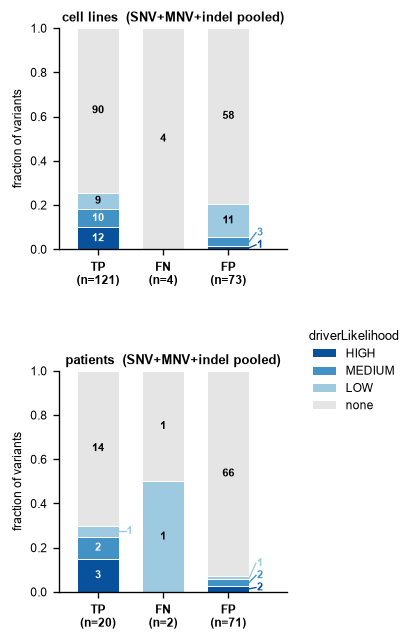

Driver-likelihood composition (gene-level; TP/FP from the panel catalog, FN from WGS):
  cell lines  TP: HIGH=12 (10%)  MEDIUM=10 (8%)  LOW=9 (7%)  none=90 (74%)
  cell lines  FN: HIGH=0 (0%)  MEDIUM=0 (0%)  LOW=0 (0%)  none=4 (100%)
  cell lines  FP: HIGH=1 (1%)  MEDIUM=3 (4%)  LOW=11 (15%)  none=58 (79%)
  patients    TP: HIGH=3 (15%)  MEDIUM=2 (10%)  LOW=1 (5%)  none=14 (70%)
  patients    FN: HIGH=0 (0%)  MEDIUM=0 (0%)  LOW=1 (50%)  none=1 (50%)
  patients    FP: HIGH=2 (3%)  MEDIUM=2 (3%)  LOW=1 (1%)  none=66 (93%)


In [10]:
def _dlik_bin(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "none"
    for name, lo, hi in DLIK_BINS:
        if lo <= v < hi:
            return name
    return "none"

def dlik_composition(group, cat):
    arm = TRUTH if cat == "FN" else TEST          # TP/FP are panel calls; FN is WGS-only
    c = Counter()
    for sid, key in cat_pairs(group, cat):
        c[_dlik_bin(DATA[arm][sid]["dlik"].get(key))] += 1
    return c

def _spread_ys(centers, ymin=0.02, ymax=0.98, gap=0.055):
    """Push side-label y positions apart so thin stacked segments stay legible."""
    if not centers:
        return []
    ys = list(centers)
    for _ in range(200):
        moved = False
        for i in range(1, len(ys)):
            if ys[i] - ys[i - 1] < gap:
                shift = (gap - (ys[i] - ys[i - 1])) / 2
                ys[i - 1] -= shift; ys[i] += shift; moved = True
        ys[0] = max(ys[0], ymin); ys[-1] = min(ys[-1], ymax)
        if not moved:
            break
    return ys

def draw_driverlik(fig, spec):
    groups = [g for g in GROUPS if GROUP_SAMPLES[g]]
    cats = ["TP", "FN", "FP"]
    sub = spec.subgridspec(len(groups), 1, hspace=0.55)
    axes = []
    for gi, g in enumerate(groups):
        ax = fig.add_subplot(sub[gi, 0])
        comps = {cat: dlik_composition(g, cat) for cat in cats}
        tots = {cat: sum(comps[cat].values()) for cat in cats}
        for xi, cat in enumerate(cats):
            denom = tots[cat] or 1; bottom = 0.0
            side = []                                  # (bin, count, segment centre) for thin slices
            for b in DLIK_ORDER:
                v = comps[cat].get(b, 0)
                if not v:
                    continue
                h = v / denom
                ax.bar(xi, h, bottom=bottom, width=0.64,
                       color=DLIK_COLORS[b], edgecolor="white", lw=0.6)
                if h >= 0.07:
                    ax.text(xi, bottom + h / 2, str(v), ha="center", va="center", fontsize=6.5,
                            weight="bold", color=_text_color(DLIK_COLORS[b]))
                else:
                    side.append((b, v, bottom + h / 2))
                bottom += h
            # thin slices get their count on the right, on a leader line
            for (b, v, cen), y in zip(side, _spread_ys([c for _, _, c in side])):
                ax.plot([xi + 0.32, xi + 0.425], [cen, y], color=DLIK_COLORS[b],
                        lw=0.8, clip_on=False, zorder=5)
                ax.text(xi + 0.44, y, str(v), ha="left", va="center", fontsize=6.5,
                        weight="bold", color=DLIK_COLORS[b], clip_on=False, zorder=6)
        ax.set_xticks(range(len(cats)))
        ax.set_xticklabels([f"{cat}\n(n={tots[cat]})" for cat in cats], fontsize=7, weight="bold")
        ax.set_xlim(-0.6, len(cats) - 0.1); ax.set_ylim(0, 1.0)
        ax.set_ylabel("fraction of variants", fontsize=7)
        ax.set_title(_group_title(g), fontsize=7.5, pad=4)
        axes.append(ax)
    fig.legend(handles=[Patch(facecolor=DLIK_COLORS[b], label=b) for b in DLIK_ORDER],
               title="driverLikelihood", loc="center left", bbox_to_anchor=(1.05, 1.0),
               bbox_transform=axes[-1].transAxes, fontsize=7, title_fontsize=7.5)
    return axes

fig = plt.figure(figsize=(3.8, 5.4))
draw_driverlik(fig, fig.add_gridspec(1, 1, left=0.18, right=0.68, top=0.94, bottom=0.07)[0, 0])
plt.show()

print("Driver-likelihood composition (gene-level; TP/FP from the panel catalog, FN from WGS):")
for g in GROUPS:
    for cat in ("TP", "FN", "FP"):
        comp = dlik_composition(g, cat); tot = sum(comp.values()) or 1
        print(f"  {GROUPS[g]['label']:11s} {cat}: " +
              "  ".join(f"{b}={comp.get(b, 0)} ({comp.get(b, 0) / tot * 100:.0f}%)"
                        for b in DLIK_ORDER))

## 10 · Composite figure

Panel A across the top, then the three benchmark panels side by side: the Venn diagrams (B), the
somatic-likelihood bars (C) and the driver-likelihood bars (D). Exported to `figures/figure_4.*`.

In [ ]:
def composite_figure():
    fig = plt.figure(figsize=(15.0, 11.0))
    outer = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.45], hspace=0.34,
                             left=0.055, right=0.905, top=0.930, bottom=0.045)
    axA = draw_burden(fig, outer[0])

    bot = outer[1].subgridspec(1, 3, width_ratios=[2.0, 1.0, 1.15], wspace=0.55)
    axB = draw_venns(fig, bot[0, 0])
    axC = draw_somlh(fig, bot[0, 1])
    axD = draw_driverlik(fig, bot[0, 2])

    burden_legend(fig, axA)
    def _title(ax, text, dy=0.014):
        p = ax.get_position()
        fig.text(p.x0, p.y1 + dy, text, fontsize=10.5, weight="bold", ha="left", va="bottom")

    tag = (f" (panel regions, VAF ≥ {round(VAF_MIN * 100)}%)" if REGION else
           f" (VAF ≥ {round(VAF_MIN * 100)}%)")
    _title(axA[0], "A · variant burden — WGS T/N vs targeted panel" + tag, dy=0.020)
    _title(axB[0][0], "B · benchmark overlap — WGS ∩ panel", dy=0.030)
    _title(axC[0], "C · somatic likelihood (TP vs FP)", dy=0.030)
    _title(axD[0], "D · driver likelihood (TP / FN / FP)", dy=0.030)
    return fig

fig = composite_figure()
stem = EXPORT_DIR / "figure_4"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()